In [ ]:
from pathlib import Path
import numpy as np
import csv
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from matplotlib.patches import Circle, Rectangle


Toolbox functions ready to define.


In [3]:
def _read_dicom(path):
    """Read one DICOM image file; fail clearly if it has no pixel data."""
    ds = pydicom.dcmread(str(path))
    if not hasattr(ds, "PixelData"):
        raise ValueError(f"No image pixel data in {path}")
    return ds

def _pixels(ds):
    """Return rescaled pixel values as floats (not necessarily calibrated HU)."""
    a = np.asarray(ds.pixel_array).astype(float)
    # DICOM can store pixel values with a linear slope/intercept conversion.
    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))
    return a * slope + intercept

def load_dicom(path, series_uid=None):
    """Load a DICOM file or a single series from a directory.

    Parameters
    ----------
    path : str or Path
        A single image file or directory containing DICOM files.
    series_uid : str or None
        Select a specific series when the directory contains several.

    Returns
    -------
    image_or_volume : ndarray
        2D for one file; 3D (slice, row, column) for a directory.
    first_dataset : pydicom Dataset
        Header of the first image in the selected series.
    datasets : list
        DICOM datasets in the same order as the returned slices.

    Assumptions: single-frame grayscale images with matching dimensions.
    Check orientation, slice spacing, pixel spacing and units before measuring.
    """
    path = Path(path)
    if path.is_file():
        ds = _read_dicom(path)
        return _pixels(ds), ds, [ds]
    if not path.is_dir():
        raise FileNotFoundError(path)
    groups = {}
    # Scan metadata first so that unrelated series are not mixed together.
    for p in sorted(path.rglob("*")):
        if not p.is_file() or p.name.startswith("."):
            continue
        try:
            h = pydicom.dcmread(str(p), stop_before_pixels=True)
            if not hasattr(h, "Rows"):
                continue
            uid = str(getattr(h, "SeriesInstanceUID", "unknown"))
            groups.setdefault(uid, []).append(p)
        except Exception:
            continue
    if not groups:
        raise ValueError("No readable DICOM image files found")
    print("Available series:")
    for uid, paths in groups.items():
        print(f"  {uid} : {len(paths)} files")
    if series_uid is None and len(groups) > 1:
        raise ValueError("Multiple series: set SERIES_UID to one listed above")
    uid = series_uid or next(iter(groups))
    if uid not in groups:
        raise ValueError("SERIES_UID not found")
    dsets = [_read_dicom(p) for p in groups[uid]]
    def sort_key(ds):
        """Sort slices by physical position if available; otherwise instance number."""
        try:
            orient = np.asarray(ds.ImageOrientationPatient, float)
            normal = np.cross(orient[:3], orient[3:])
            return float(np.dot(np.asarray(ds.ImagePositionPatient, float), normal))
        except Exception:
            return float(getattr(ds, "InstanceNumber", 0))
    dsets.sort(key=sort_key)
    arrs = [_pixels(ds) for ds in dsets]
    if len({a.shape for a in arrs}) != 1:
        raise ValueError("Different image shapes within series")
    return np.stack(arrs, axis=0), dsets[0], dsets

def pixel_spacing_mm(ds):
    """Return (row_spacing, column_spacing) in mm/pixel, or None if absent."""
    if hasattr(ds, "PixelSpacing"):
        return tuple(float(v) for v in ds.PixelSpacing)
    return None

def show_metadata(ds, arr):
    """Print image dimensions and metadata needed to judge measurement validity."""
    print("Array shape:", arr.shape)
    for field in ["Modality", "SeriesDescription", "PixelSpacing", "SliceThickness", "SpacingBetweenSlices", "PhotometricInterpretation", "RescaleSlope", "RescaleIntercept"]:
        print(f"{field}: {getattr(ds, field, 'not provided')}")
    print("WARNING: confirm image geometry, pixel calibration, and orientation before physical measurements.")

# PixelSpacing is (row, column) mm/pixel, NOT (x, y).
# Slice thickness is not necessarily the distance between adjacent slice centres.
# Do not combine different series without checking geometry and scaling.
# This basic loader is not designed for colour ultrasound or multiframe data.
def show_image(img, spacing=None, vmin=None, vmax=None, title="Image"):
    """Display a 2D image with optional physical axes.

    spacing : (row_mm, column_mm) or None
        If omitted, axes show pixels. If supplied, axes show mm.
    vmin, vmax : optional display limits
        Change image appearance only; do not change underlying pixel values.
    Returns (figure, axes) for further annotations or saving.
    """
    fig, ax = plt.subplots(figsize=(7, 5))
    if spacing is None:
        ax.imshow(img, cmap="gray", origin="upper", vmin=vmin, vmax=vmax)
        ax.set(xlabel="Column (pixels)", ylabel="Row (pixels)")
    else:
        dy, dx = spacing  # DICOM stores row spacing before column spacing.
        ax.imshow(img, cmap="gray", origin="upper", vmin=vmin, vmax=vmax,
                  extent=[0, img.shape[1]*dx, img.shape[0]*dy, 0])
        ax.set(xlabel="Horizontal distance (mm)", ylabel="Vertical distance (mm)")
    ax.set_title(title)
    return fig, ax
def distance_mm(p1_xy, p2_xy, spacing):
    """Distance in mm between two pixel positions (x=column, y=row).

    spacing must be verified (row_mm, column_mm). Suitable for a 2D
    image with orthogonal in-plane pixel axes; not a 3D distance.
    """
    if spacing is None:
        raise ValueError("Physical pixel spacing not verified")
    dy, dx = spacing
    # Convert horizontal and vertical pixel differences separately to mm.
    return float(np.hypot((p2_xy[0]-p1_xy[0])*dx, (p2_xy[1]-p1_xy[1])*dy))

def line_profile(img, p1_xy, p2_xy, spacing=None, samples=300):
    """Sample intensities along a line between two (column, row) positions.

    Returns (distance_along_line, intensity_values, distance_unit).
    Uses nearest-neighbour sampling: repeated pixels and stair-step edges
    are possible. Choose endpoints based on your scientific question.
    """
    x = np.linspace(p1_xy[0], p2_xy[0], samples)
    y = np.linspace(p1_xy[1], p2_xy[1], samples)
    # Round sampling locations to nearest existing pixels (no interpolation).
    xi = np.clip(np.rint(x).astype(int), 0, img.shape[1]-1)
    yi = np.clip(np.rint(y).astype(int), 0, img.shape[0]-1)
    values = img[yi, xi]
    if spacing is None:
        dist = np.linspace(0, np.hypot(x[-1]-x[0], y[-1]-y[0]), samples)
        unit = "pixels"
    else:
        dist = np.linspace(0, distance_mm(p1_xy, p2_xy, spacing), samples)
        unit = "mm"
    return dist, values, unit
def roi_values(img, roi):
    """Return pixel intensities inside a rectangular ROI.

    roi = (x, y, width, height), all in pixels; x is column, y is row.
    The rectangle must lie completely inside the 2D image.
    """
    x, y, w, h = map(int, roi)
    if w <= 0 or h <= 0 or x < 0 or y < 0 or x+w > img.shape[1] or y+h > img.shape[0]:
        raise ValueError(f"ROI outside image: {roi}")
    # Array indexing is [row, column], the reverse of (x, y) notation.
    return np.asarray(img[y:y+h, x:x+w], float).ravel()

def roi_summary(img, roi):
    """Summarise an ROI with count, mean, median and within-ROI SD.

    Output intensity units are those of the input image. The standard
    deviation reflects ALL variation within the ROI (including structure,
    artefacts and noise); it is not automatically a noise estimate.
    """
    a = roi_values(img, roi)
    return {"n_pixels": len(a), "mean": float(a.mean()),
            "std_within_roi": float(a.std(ddof=1)) if len(a)>1 else np.nan,
            "median": float(np.median(a))}

# Analysis of the caper body 

In [ ]:
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

HELICAL_PATH = Path(
    r"C:\Users\mamag\OneDrive\Desktop\BA5\Medical Imaging\Project\CT\Dtu2_DTU2\20260922\Helical"
)

AXIAL_PATH = Path(r"C:\Users\mamag\OneDrive\Desktop\BA5\Medical Imaging\Project\CT\Dtu2_DTU2\20260922\Axial_2")

OUTPUT_DIR = HELICAL_PATH.parent / "python_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. ANALYSIS PARAMETERS
# ============================================================

CASES = [
    {
        "name": "Helical",
        "path": HELICAL_PATH,
        "series_uid": None,
        "frame_number": 115,
        "reverse_stack": False,

        "window": 80,
        "level": 40,

        "circle": {
            "center_x": 179.25,
            "center_y": 183.74,
            "radius": 8.99,
        },

        "rectangle": {
            "center_x": 196.69,
            "center_y": 178.15,
            "width": 75.91,
            "height": 48.80,
        },

        "expected_pixels": 700,
        "expected_area_mm2": 253.6,

        "measurement_line": None,
    },

    {
        "name": "Axial",
        "path": AXIAL_PATH,
        "series_uid": None,
        "frame_number": 5,
        "reverse_stack": False,

        "window": 80,
        "level": 40,

        "circle": {
            "center_x": 180.75,
            "center_y": 213.98,
            "radius": 9.40,
        },

        "rectangle": {
            "center_x": 198.17,
            "center_y": 210.68,
            "width": 76.40,
            "height": 50.15,
        },

        "expected_pixels": None,
        "expected_area_mm2": None,

        "measurement_line": None,
    },
]


# ============================================================
# 3. FRAME SELECTION
# ============================================================

def select_frame(volume, datasets, frame_number):

    if volume.ndim == 2:
        return volume, datasets[0], 1

    index = frame_number - 1

    return volume[index], datasets[index], volume.shape[0]


# ============================================================
# 4. CIRCULAR ROI MASK
# ============================================================

def circle_mask_mm(image, center_x, center_y, radius, spacing):

    dy, dx = spacing
    rows, cols = image.shape

    x_positions = np.arange(cols) * dx
    y_positions = np.arange(rows) * dy

    distance_squared = (
        (x_positions[None, :] - center_x) ** 2
        + (y_positions[:, None] - center_y) ** 2
    )

    return distance_squared <= radius ** 2


# ============================================================
# 5. ROI STATISTICS
# ============================================================

def circle_summary(image, mask):

    values = image[mask]

    return {
        "n_pixels": int(len(values)),
        "mean_HU": float(np.mean(values)),
        "median_HU": float(np.median(values)),
        "min_HU": float(np.min(values)),
        "max_HU": float(np.max(values)),
        "std_sample_HU": float(np.std(values, ddof=1)),
        "std_population_HU": float(np.std(values, ddof=0)),
    }


# ============================================================
# 6. WINDOW / LEVEL
# ============================================================

def dicom_window_limits(window, level):

    lower = level - 0.5 - (window - 1) / 2
    upper = level - 0.5 + (window - 1) / 2

    return lower, upper


# ============================================================
# 7. IMAGE DISPLAY
# ============================================================

def plot_roi(
    image,
    spacing,
    circle,
    rectangle,
    window,
    level,
    stats,
    name,
    frame_number,
    output_path,
    measurement_line=None,
):

    dy, dx = spacing
    rows, cols = image.shape

    # Pixel-centre coordinates, with (0, 0) at the upper-left.
    extent = [
        -dx / 2,
        (cols - 0.5) * dx,
        (rows - 0.5) * dy,
        -dy / 2,
    ]

    vmin, vmax = dicom_window_limits(window, level)

    fig, ax = plt.subplots(figsize=(10, 8))

    ax.imshow(
        image,
        cmap="gray",
        origin="upper",
        extent=extent,
        vmin=vmin,
        vmax=vmax,
    )

    # Circular ROI
    circle_patch = Circle(
        (circle["center_x"], circle["center_y"]),
        radius=circle["radius"],
        fill=False,
        edgecolor="yellow",
        linewidth=2,
    )

    ax.add_patch(circle_patch)

    # Optional measurement line
    if measurement_line is not None:

        x1, y1 = measurement_line["p1"]
        x2, y2 = measurement_line["p2"]

        ax.plot(
            [x1, x2],
            [y1, y2],
            color="yellow",
            linewidth=2,
            marker="o",
            markersize=5,
        )

        text_x = 150 * dx
        text_y = 750 * dy

        ax.text(
            text_x,
            text_y,
            measurement_line["value"],
            color="yellow",
            fontsize=12,
            fontweight="bold",
            bbox=dict(
                facecolor="black",
                edgecolor="none",
                pad=4,
            ),
        )

    # Zoom region
    margin = 0.10 * max(
        rectangle["width"],
        rectangle["height"],
    )

    x_min = rectangle["center_x"] - rectangle["width"] / 2 - margin
    x_max = rectangle["center_x"] + rectangle["width"] / 2 + margin

    y_min = rectangle["center_y"] - rectangle["height"] / 2 - margin
    y_max = rectangle["center_y"] + rectangle["height"] / 2 + margin

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min)
    ax.set_aspect("equal")


    ax.set_title(
        f"{name} CT - Frame {frame_number}",
        fontsize=18,
        fontweight="bold",
        pad=15,
    )

    ax.set_xlabel(
        "Horizontal position (mm)",
        fontsize=16,
        fontweight="bold",
    )

    ax.set_ylabel(
        "Vertical position (mm)",
        fontsize=16,
        fontweight="bold",
    )

    ax.tick_params(axis="both", labelsize=14)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

    # Window / Level
    ax.text(
        0.02,
        0.97,
        f"Window: {window} | Level: {level}",
        transform=ax.transAxes,
        fontsize=15,
        color="yellow",
        fontweight="bold",
        verticalalignment="top",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            pad=5,
        ),
    )

    # HU statistics
    ax.text(
        0.02,
        0.02,
        (
            f"Mean HU: {stats['mean_HU']:.1f}\n"
            f"Median HU: {stats['median_HU']:.1f}\n"
            f"Pixels: {stats['n_pixels']}"
        ),
        transform=ax.transAxes,
        fontsize=12,
        color="yellow",
        fontweight="bold",
        verticalalignment="bottom",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            pad=5,
        ),
    )

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


# ============================================================
# 8. COMPLETE ANALYSIS
# ============================================================

def analyse_case(case):

    print(f"\n{'=' * 50}")
    print(f"ANALYSIS: {case['name'].upper()}")
    print(f"{'=' * 50}")

    volume, first_ds, datasets = load_dicom(
        case["path"],
        series_uid=case["series_uid"],
    )

    if case["reverse_stack"]:
        volume = volume[::-1]
        datasets = datasets[::-1]

    image, ds, total_frames = select_frame(
        volume,
        datasets,
        case["frame_number"],
    )

    print(f"Selected frame: {case['frame_number']} / {total_frames}")
    print("Instance number:", getattr(ds, "InstanceNumber", "N/A"))
    print("Image position:", getattr(ds, "ImagePositionPatient", "N/A"))

    show_metadata(ds, image)

    spacing = pixel_spacing_mm(ds)
    dy, dx = spacing

    print(f"Row spacing: {dy:.5f} mm/pixel")
    print(f"Column spacing: {dx:.5f} mm/pixel")

    pixel_area = dy * dx

    # Circular ROI
    circle = case["circle"]

    mask = circle_mask_mm(
        image,
        circle["center_x"],
        circle["center_y"],
        circle["radius"],
        spacing,
    )

    stats = circle_summary(image, mask)

    area_from_pixels = stats["n_pixels"] * pixel_area
    theoretical_area = np.pi * circle["radius"] ** 2

    print("\n--- CIRCULAR ROI RESULTS ---")
    print(f"Number of pixels: {stats['n_pixels']}")
    print(f"Mean HU: {stats['mean_HU']:.3f}")
    print(f"Median HU: {stats['median_HU']:.3f}")
    print(f"Minimum HU: {stats['min_HU']:.3f}")
    print(f"Maximum HU: {stats['max_HU']:.3f}")
    print(f"Sample SD: {stats['std_sample_HU']:.3f}")
    print(f"Population SD: {stats['std_population_HU']:.3f}")
    print(f"Area from pixels: {area_from_pixels:.3f} mm²")
    print(f"Theoretical circle area: {theoretical_area:.3f} mm²")

    if case["expected_pixels"] is not None:
        print("\n--- COMPARISON WITH WEASIS ---")
        print(f"Weasis pixels: {case['expected_pixels']}")
        print(f"Python pixels: {stats['n_pixels']}")
        print(f"Weasis area: {case['expected_area_mm2']} mm²")
        print(f"Python area: {area_from_pixels:.3f} mm²")

    # Figure
    figure_path = OUTPUT_DIR / f"{case['name'].lower()}_roi.png"

    plot_roi(
        image=image,
        spacing=spacing,
        circle=circle,
        rectangle=case["rectangle"],
        window=case["window"],
        level=case["level"],
        stats=stats,
        name=case["name"],
        frame_number=case["frame_number"],
        output_path=figure_path,
        measurement_line=case["measurement_line"],
    )

    return {
        "series": case["name"],
        "frame": case["frame_number"],
        "total_frames": total_frames,
        "window": case["window"],
        "level": case["level"],
        "row_spacing_mm": dy,
        "column_spacing_mm": dx,
        "n_pixels": stats["n_pixels"],
        "area_from_pixels_mm2": area_from_pixels,
        "theoretical_area_mm2": theoretical_area,
        "mean_HU": stats["mean_HU"],
        "median_HU": stats["median_HU"],
        "min_HU": stats["min_HU"],
        "max_HU": stats["max_HU"],
        "std_sample_HU": stats["std_sample_HU"],
        "std_population_HU": stats["std_population_HU"],
    }


# ============================================================
# 9. RUN ANALYSIS AND EXPORT RESULTS
# ============================================================

all_results = []

for case in CASES:
    result = analyse_case(case)
    all_results.append(result)

csv_path = OUTPUT_DIR / "CT_HU_results.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=all_results[0].keys(),
    )

    writer.writeheader()
    writer.writerows(all_results)

print("\nAnalysis completed.")
print("Results saved to:", csv_path)


ANALYSIS: HELICAL
Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.620 : 520 files
Selected frame: 115 / 520
Instance number: 406
Image position: [-150.000, -150.000, 71.375]
Array shape: (512, 512)
Modality: CT
SeriesDescription: Helical
PixelSpacing: [0.585938, 0.585938]
SliceThickness: 0.625000
SpacingBetweenSlices: 0.625000
PhotometricInterpretation: MONOCHROME2
RescaleSlope: 1
RescaleIntercept: -1024
Row spacing: 0.58594 mm/pixel
Column spacing: 0.58594 mm/pixel

--- CIRCULAR ROI RESULTS ---
Number of pixels: 741
Mean HU: 30.045
Median HU: 30.000
Minimum HU: 6.000
Maximum HU: 55.000
Sample SD: 8.703
Population SD: 8.697
Area from pixels: 254.403 mm²
Theoretical circle area: 253.904 mm²

--- COMPARISON WITH WEASIS ---
Weasis pixels: 700
Python pixels: 741
Weasis area: 253.6 mm²
Python area: 254.403 mm²


<Figure size 1000x800 with 1 Axes>


ANALYSIS: AXIAL
Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.384 : 16 files
Selected frame: 5 / 16
Instance number: 5
Image position: [-150.000, -180.000, 72.000]
Array shape: (512, 512)
Modality: CT
SeriesDescription: Axial 2
PixelSpacing: [0.585938, 0.585938]
SliceThickness: 1.250000
SpacingBetweenSlices: 1.250000
PhotometricInterpretation: MONOCHROME2
RescaleSlope: 1
RescaleIntercept: -1024
Row spacing: 0.58594 mm/pixel
Column spacing: 0.58594 mm/pixel

--- CIRCULAR ROI RESULTS ---
Number of pixels: 809
Mean HU: 27.942
Median HU: 28.000
Minimum HU: 10.000
Maximum HU: 51.000
Sample SD: 8.211
Population SD: 8.206
Area from pixels: 277.749 mm²
Theoretical circle area: 277.591 mm²


<Figure size 1000x800 with 1 Axes>


Analysis completed.
Results saved to: C:\Users\mamag\OneDrive\Desktop\BA5\Medical Imaging\Project\CT\Dtu2_DTU2\20260922\python_analysis\CT_HU_results.csv


Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.620 : 520 files
Number of frames: 520
Pixel spacing: (0.585938, 0.585938)
Frame 423: Mean HU = 52.47, Min = 36.00, Max = 74.00, Pixels = 19
Frame 426: Mean HU = 55.28, Min = 29.00, Max = 86.00, Pixels = 18
Frame 429: Mean HU = 45.89, Min = 29.00, Max = 66.00, Pixels = 18
Frame 432: Mean HU = 39.44, Min = 18.00, Max = 57.00, Pixels = 16
Frame 435: Mean HU = 44.83, Min = 27.00, Max = 66.00, Pixels = 12
Frame 438: Mean HU = 39.67, Min = 22.00, Max = 56.00, Pixels = 12
Frame 441: Mean HU = 36.36, Min = 18.00, Max = 54.00, Pixels = 14
Frame 444: Mean HU = 35.00, Min = 25.00, Max = 45.00, Pixels = 13
Frame 447: Mean HU = 30.29, Min = 15.00, Max = 49.00, Pixels = 17
Frame 450: Mean HU = 31.21, Min = 21.00, Max = 45.00, Pixels = 14
Frame 453: Mean HU = 30.06, Min = 11.00, Max = 53.00, Pixels = 18
Frame 456: Mean HU = 40.33, Min = 30.00, Max = 52.00, Pixels = 12
Frame 459: Mean HU = 36.75, Min = 25.00, Max = 53.00, Pixels = 16
Frame

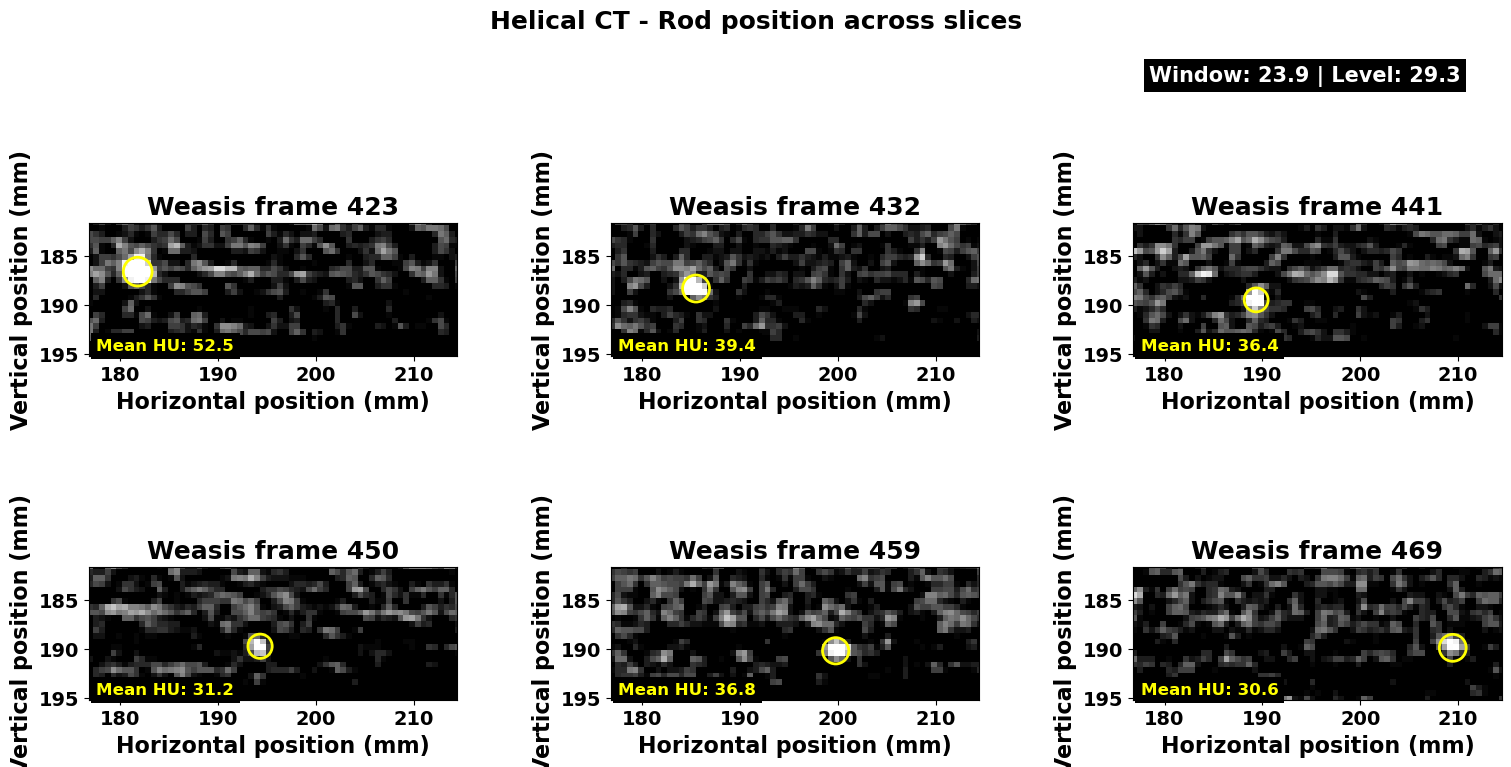


Results exported to: C:\Users\mamag\OneDrive\Desktop\BA5\Medical Imaging\Project\CT\Dtu2_DTU2\20260922\python_analysis


In [5]:

from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


# ============================================================
# 1. SETTINGS
# ============================================================

HELICAL_PATH = Path(
    r"C:\Users\mamag\OneDrive\Desktop\BA5\Medical Imaging\Project\CT\Dtu2_DTU2\20260922\Helical"
)

OUTPUT_DIR = HELICAL_PATH.parent / "python_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SLICE_SPACING = 0.625  # mm
WINDOW = 23.9
LEVEL = 29.3

# Pixel coordinates are measured from the upper-left pixel centre.
# X increases to the right and Y increases downwards.


# ============================================================
# 2. WEASIS MEASUREMENTS
# ============================================================

MEASUREMENTS = [
    {"frame": 423, "x": 181.800000, "y": 186.600000, "radius": 1.470000},
    {"frame": 426, "x": 182.991745, "y": 187.205271, "radius": 1.461554},
    {"frame": 429, "x": 184.174112, "y": 187.821535, "radius": 1.423916},
    {"frame": 432, "x": 185.489559, "y": 188.327239, "radius": 1.377818},
    {"frame": 435, "x": 186.624524, "y": 188.931308, "radius": 1.127145},
    {"frame": 438, "x": 187.847554, "y": 189.242601, "radius": 1.142117},
    {"frame": 441, "x": 189.363566, "y": 189.486148, "radius": 1.222429},
    {"frame": 444, "x": 190.869492, "y": 189.786859, "radius": 1.202336},
    {"frame": 447, "x": 192.307363, "y": 189.985624, "radius": 1.359626},
    {"frame": 450, "x": 194.302338, "y": 189.744851, "radius": 1.240408},
    {"frame": 453, "x": 195.633935, "y": 190.037618, "radius": 1.438268},
    {"frame": 456, "x": 197.882665, "y": 190.181720, "radius": 1.120590},
    {"frame": 459, "x": 199.756264, "y": 190.209322, "radius": 1.341994},
    {"frame": 462, "x": 203.085541, "y": 190.026667, "radius": 1.217937},
    {"frame": 465, "x": 205.662125, "y": 190.020695, "radius": 1.397942},
    {"frame": 468, "x": 209.018146, "y": 189.637357, "radius": 1.641419},
    {"frame": 469, "x": 209.448440, "y": 189.907985, "radius": 1.376543},
]


# ============================================================
# 3. FRAME SELECTION
# ============================================================

def get_weasis_frame(volume, datasets, frame_number):
    """
    Get a frame using the 1-based frame numbering from Weasis.
    """
    index = frame_number - 1

    return volume[index], datasets[index]


# ============================================================
# 4. CIRCULAR ROI
# ============================================================

def create_circle_mask(image, center_x, center_y, radius, spacing):

    dy, dx = spacing
    rows, cols = image.shape

    x_positions = np.arange(cols) * dx
    y_positions = np.arange(rows) * dy

    distance_squared = (
        (x_positions[None, :] - center_x) ** 2
        + (y_positions[:, None] - center_y) ** 2
    )

    return distance_squared <= radius ** 2


# ============================================================
# 5. HU STATISTICS
# ============================================================

def calculate_statistics(image, mask, spacing):

    values = image[mask]

    dy, dx = spacing
    pixel_area = dy * dx

    area = len(values) * pixel_area

    return {
        "n_pixels": int(len(values)),
        "area_mm2": float(area),
        "mean_HU": float(np.mean(values)),
        "median_HU": float(np.median(values)),
        "min_HU": float(np.min(values)),
        "max_HU": float(np.max(values)),
        "std_HU": float(np.std(values, ddof=1)),
    }


# ============================================================
# 6. WINDOW / LEVEL
# ============================================================

def window_limits(window, level):

    lower = level - 0.5 - (window - 1) / 2
    upper = level - 0.5 + (window - 1) / 2

    return lower, upper


# ============================================================
# 7. HU ANALYSIS OF ALL MEASUREMENTS
# ============================================================

def analyse_tail(volume, datasets, spacing):

    dy, dx = spacing

    results = []

    for measurement in MEASUREMENTS:

        frame = measurement["frame"]

        image, ds = get_weasis_frame(
            volume,
            datasets,
            frame,
        )

        mask = create_circle_mask(
            image,
            measurement["x"],
            measurement["y"],
            measurement["radius"],
            spacing,
        )

        stats = calculate_statistics(
            image,
            mask,
            spacing,
        )

        result = {
            "frame": frame,
            "center_x_mm": measurement["x"],
            "center_y_mm": measurement["y"],
            "radius_mm": measurement["radius"],
            "roi_diameter_mm": 2 * measurement["radius"],
            **stats,
        }

        results.append(result)

        print(
            f"Frame {frame}: "
            f"Mean HU = {stats['mean_HU']:.2f}, "
            f"Min = {stats['min_HU']:.2f}, "
            f"Max = {stats['max_HU']:.2f}, "
            f"Pixels = {stats['n_pixels']}"
        )

    return results


# ============================================================
# 8. APPROXIMATE GEOMETRICAL MEASUREMENTS
# ============================================================

def calculate_geometry():

    frames = np.array([m["frame"] for m in MEASUREMENTS])

    x = np.array([m["x"] for m in MEASUREMENTS])
    y = np.array([m["y"] for m in MEASUREMENTS])
    radius = np.array([m["radius"] for m in MEASUREMENTS])

    z = (frames - frames[0]) * SLICE_SPACING

    dx = np.diff(x)
    dy = np.diff(y)
    dz = np.diff(z)

    segment_lengths = np.sqrt(
        dx ** 2 + dy ** 2 + dz ** 2
    )

    trajectory_length = np.sum(segment_lengths)

    endpoint_distance = np.sqrt(
        (x[-1] - x[0]) ** 2
        + (y[-1] - y[0]) ** 2
        + (z[-1] - z[0]) ** 2
    )

    diameters = 2 * radius

    return {
        "trajectory_length_mm": trajectory_length,
        "endpoint_distance_mm": endpoint_distance,
        "mean_roi_diameter_mm": np.mean(diameters),
        "std_roi_diameter_mm": np.std(diameters, ddof=1),
        "median_roi_diameter_mm": np.median(diameters),
        "min_roi_diameter_mm": np.min(diameters),
        "max_roi_diameter_mm": np.max(diameters),
        "total_volume_mm3": np.pi*np.mean(radius)**2*trajectory_length,
    }


# ============================================================
# 9. PLOT REPRESENTATIVE FRAMES
# ============================================================

def plot_tail(volume, datasets, spacing, results):

    selected_frames = [423, 432, 441, 450, 459, 469]

    dy, dx = spacing

    rows, cols = volume[0].shape

    extent = [
        -dx / 2,
        (cols - 0.5) * dx,
        (rows - 0.5) * dy,
        -dy / 2,
    ]

    vmin, vmax = window_limits(WINDOW, LEVEL)

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 8),
        layout="constrained",
    )

    fig.get_layout_engine().set(
        wspace=0.15,         
        hspace=0.0,         
        rect=(0, 0, 1, 0.9),)

    axes = axes.flatten()
    # Same physical zoom for all six frames.
    x_min = min(m["x"] for m in MEASUREMENTS) - 5
    x_max = max(m["x"] for m in MEASUREMENTS) + 5

    y_min = min(m["y"] for m in MEASUREMENTS) - 5
    y_max = max(m["y"] for m in MEASUREMENTS) + 5

    for ax, frame in zip(axes, selected_frames):

        measurement = next(
            m for m in MEASUREMENTS
            if m["frame"] == frame
        )

        result = next(
            r for r in results
            if r["frame"] == frame
        )

        image, ds = get_weasis_frame(
            volume,
            datasets,
            frame,
        )

        ax.imshow(
            image,
            cmap="gray",
            origin="upper",
            extent=extent,
            vmin=vmin,
            vmax=vmax,
        )

        # Yellow circle around the rod.
        circle = Circle(
            (measurement["x"], measurement["y"]),
            measurement["radius"],
            fill=False,
            edgecolor="yellow",
            linewidth=2,
        )

        ax.add_patch(circle)

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_max, y_min)
        ax.set_aspect("equal")

        ax.set_title(
            f"Weasis frame {frame}",
            fontsize=18,
            fontweight="bold",
        )

        ax.set_xlabel(
            "Horizontal position (mm)",
            fontsize=16,
            fontweight="bold",
        )

        ax.set_ylabel(
            "Vertical position (mm)",
            fontsize=16,
            fontweight="bold",
        )

        ax.tick_params(
            axis="both",
            labelsize=14,
        )

        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_fontweight("bold")


        ax.text(
            0.02,
            0.02,
            f"Mean HU: {result['mean_HU']:.1f}",
            transform=ax.transAxes,
            fontsize=12,
            color="yellow",
            fontweight="bold",
            verticalalignment="bottom",
            bbox=dict(
                facecolor="black",
                edgecolor="none",
                pad=4,
            ),
        )

    fig.suptitle(
        "Helical CT - Rod position across slices",
        fontsize=18,
        fontweight="bold",
    )
    fig.text(
        0.97, 0.925,
        f"Window: {WINDOW} | Level: {LEVEL}",
        ha="right",
        va="top",
        fontsize=15,
        fontweight="bold",
        color="white",
        bbox=dict(facecolor="black", edgecolor="none")
    )
    

    output_path = OUTPUT_DIR / "tail_frames.png"

    fig.savefig(
        output_path,
        dpi=300,
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 10. EXPORT RESULTS
# ============================================================

def export_results(results, geometry):

    csv_path = OUTPUT_DIR / "tail_HU_results.csv"

    with open(csv_path, "w", newline="", encoding="utf-8") as file:

        writer = csv.DictWriter(
            file,
            fieldnames=results[0].keys(),
        )

        writer.writeheader()
        writer.writerows(results)

    summary_path = OUTPUT_DIR / "tail_geometry_summary.csv"

    with open(summary_path, "w", newline="", encoding="utf-8") as file:

        writer = csv.writer(file)

        writer.writerow(["Parameter", "Value", "Unit"])

        writer.writerow([
            "Approximate trajectory length",
            geometry["trajectory_length_mm"],
            "mm",
        ])

        writer.writerow([
            "Endpoint distance",
            geometry["endpoint_distance_mm"],
            "mm",
        ])

        writer.writerow([
            "Mean ROI diameter",
            geometry["mean_roi_diameter_mm"],
            "mm",
        ])

        writer.writerow([
            "SD of ROI diameter",
            geometry["std_roi_diameter_mm"],
            "mm",
        ])

        writer.writerow([
            "Median ROI diameter",
            geometry["median_roi_diameter_mm"],
            "mm",
        ])

        writer.writerow([
            "Minimum ROI diameter",
            geometry["min_roi_diameter_mm"],
            "mm",
        ])

        writer.writerow([
            "Maximum ROI diameter",
            geometry["max_roi_diameter_mm"],
            "mm",
        ])

    print("\nResults exported to:", OUTPUT_DIR)


# ============================================================
# 11. RUN ANALYSIS
# ============================================================
DICOM_PATH = Path(
    r"C:\Users\mamag\OneDrive\Desktop\BA5\Medical Imaging\Project\CT\Dtu2_DTU2\20260922\Helical"
)

# Load DICOM series
volume, ds, datasets = load_dicom(DICOM_PATH)

# Reverse the order to match Weasis
volume = volume[::-1]
datasets = datasets[::-1]
spacing = pixel_spacing_mm(datasets[0])

print("Number of frames:", len(datasets))
print("Pixel spacing:", spacing)

results = analyse_tail(
    volume,
    datasets,
    spacing,
)

geometry = calculate_geometry()

print("\n--- GEOMETRICAL RESULTS ---")

for name, value in geometry.items():
    print(f"{name}: {value:.3f}")

plot_tail(
    volume,
    datasets,
    spacing,
    results,
)

export_results(
    results,
    geometry,
)


In [ ]:
def _tag_range(datasets, name, fmt="{:g}"):
    vals = [float(getattr(d, name)) for d in datasets
            if getattr(d, name, None) not in (None, "")]
    if not vals:
        return "not provided"
    lo, hi = min(vals), max(vals)
    return fmt.format(lo) if lo == hi else f"{fmt.format(lo)}-{fmt.format(hi)} (mean {fmt.format(np.mean(vals))})"

def _tag_text(datasets, name):
    vals = sorted({str(getattr(d, name)).strip() for d in datasets
                   if getattr(d, name, None) not in (None, "")})
    return " / ".join(vals) if vals else "not provided"

def ct_acquisition_summary(name, datasets):
    ds = datasets[0]
    orient = np.asarray(ds.ImageOrientationPatient, float)
    normal = np.cross(orient[:3], orient[3:])
    z = np.array([np.dot(np.asarray(d.ImagePositionPatient, float), normal) for d in datasets])
    dz = np.abs(np.diff(z))
    s = {
        "manufacturer": _tag_text(datasets, "Manufacturer"),
        "model": _tag_text(datasets, "ManufacturerModelName"),
        "scan_options": _tag_text(datasets, "ScanOptions"),
        "n_images": len(datasets),
        "slice_thickness_mm": _tag_range(datasets, "SliceThickness", "{:.3f}"),
        "spacing_from_positions_mm": f"{np.median(dz):.3f} (min {dz.min():.3f}, max {dz.max():.3f})",
        "pixel_spacing_mm": " x ".join(f"{float(v):.6f}" for v in ds.PixelSpacing),
        "matrix": f"{ds.Rows} x {ds.Columns}",
        "rescale": f"{float(getattr(ds,'RescaleSlope',1)):g} / {float(getattr(ds,'RescaleIntercept',0)):g}",
        "kVp": _tag_range(datasets, "KVP"),
        "tube_current_mA": _tag_range(datasets, "XRayTubeCurrent"),
        "exposure_mAs": _tag_range(datasets, "Exposure"),
        "kernel": _tag_text(datasets, "ConvolutionKernel"),
        "pitch": _tag_text(datasets, "SpiralPitchFactor"),
        "CTDIvol_mGy": _tag_range(datasets, "CTDIvol", "{:.2f}"),
    }
    print(f"\n===== {name} =====")
    for k, v in s.items():
        print(f"{k:28s}: {v}")
    return s

_, _, ds_hel = load_dicom(HELICAL_PATH)
_, _, ds_ax  = load_dicom(AXIAL_PATH)
hel = ct_acquisition_summary("Helical", ds_hel)
ax_ = ct_acquisition_summary("Axial",   ds_ax)

# Rows to paste in the LaTeX table
print(r"Tube voltage (kV) & " + f"{hel['kVp']} & {ax_['kVp']} " + r"\\")
print(r"Tube current (mA) & " + f"{hel['tube_current_mA']} & {ax_['tube_current_mA']} " + r"\\")
print(r"Reconstruction kernel & " + f"{hel['kernel']} & {ax_['kernel']} " + r"\\")
print("Scanner:", hel["manufacturer"], hel["model"])

Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.620 : 520 files
Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.384 : 16 files

===== Helical =====
manufacturer                : GE MEDICAL SYSTEMS
model                       : Discovery MI
scan_options                : HELICAL MODE
n_images                    : 520
slice_thickness_mm          : 0.625
spacing_from_positions_mm   : 0.625 (min 0.625, max 0.625)
pixel_spacing_mm            : 0.585938 x 0.585938
matrix                      : 512 x 512
rescale                     : 1 / -1024
kVp                         : 100
tube_current_mA             : 300
exposure_mAs                : 4
kernel                      : STANDARD
pitch                       : 0.984375
CTDIvol_mGy                 : not provided

===== Axial =====
manufacturer                : GE MEDICAL SYSTEMS
model                       : Discovery MI
scan_options                : AXIAL MODE
n_images                    : 16
slice_thickness_mm    

Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.620 : 520 files
--- Helical (frame 115) ---
ROI 1: 17.2 HU (SD = 6.0, n = 749)
ROI 2: 16.6 HU (SD = 5.6, n = 749)
ROI 3: 17.6 HU (SD = 5.6, n = 749)

Medium mean HU: 17.10 HU


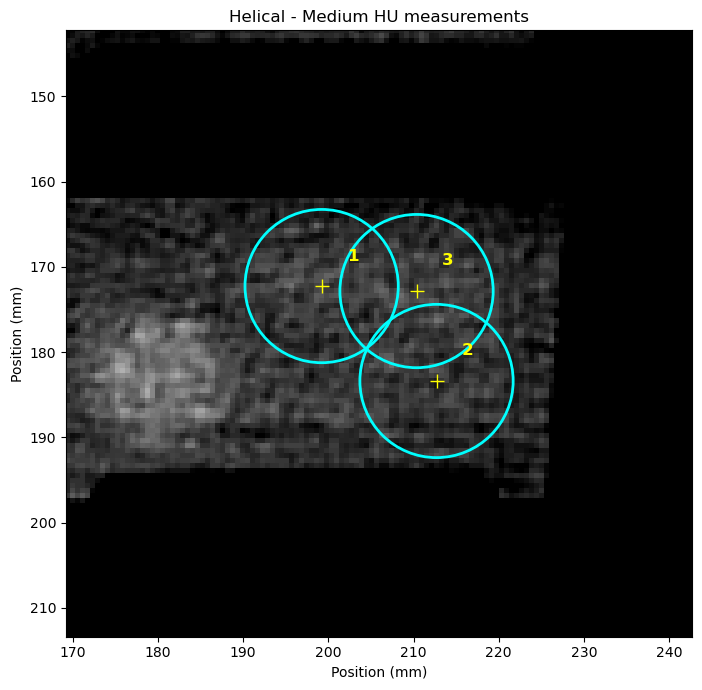

Available series:
  1.2.840.113619.2.25.4.123437670.1790086630.384 : 16 files
--- Axial (frame 5) ---
ROI 1: 14.0 HU (SD = 3.0, n = 805)
ROI 2: 13.6 HU (SD = 2.9, n = 805)
ROI 3: 14.1 HU (SD = 2.7, n = 805)

Medium mean HU: 13.90 HU


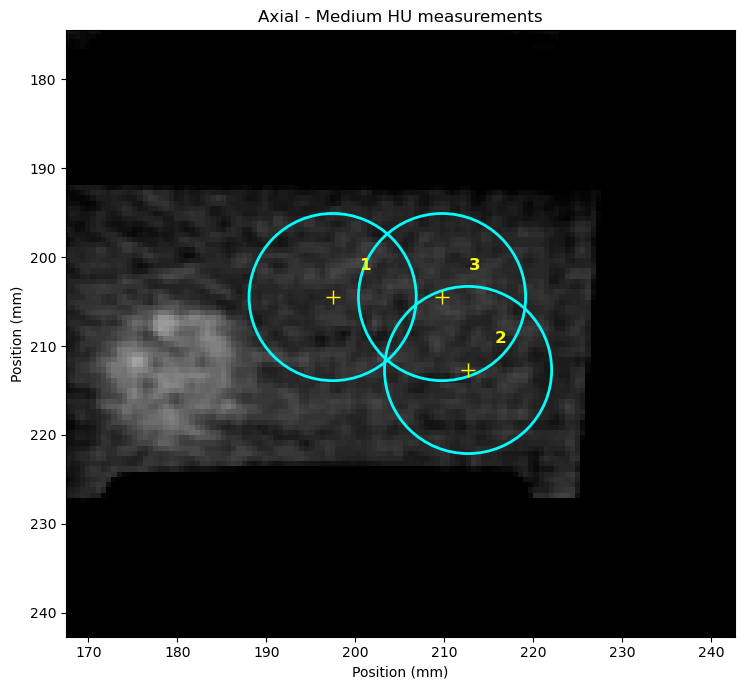

In [8]:

def circle_roi_values(img, roi, spacing):
    """Return pixel intensities inside a circular ROI.

    roi = {"x": x, "y": y, "r": radius}
    x and y are expressed in pixels.
    r is expressed in mm.
    spacing = (dy, dx), in mm/pixel.
    """
    x, y, r = roi["x"], roi["y"], roi["r"]
    dy, dx = spacing

    rows, cols = np.indices(img.shape)

    mask = ((cols - x) * dx)**2 + ((rows - y) * dy)**2 <= r**2

    if not mask.any():
        raise ValueError(f"Empty circular ROI: {roi}")

    return np.asarray(img[mask], float)


def circle_roi_summary(img, roi, spacing):
    """Summarise a circular ROI with count, mean, median and SD."""

    a = circle_roi_values(img, roi, spacing)

    return {
        "n_pixels": len(a),
        "mean_HU": float(a.mean()),
        "std_sample_HU": float(a.std(ddof=1)) if len(a) > 1 else np.nan,
        "median_HU": float(np.median(a)),
        "min_HU": float(a.min()),
        "max_HU": float(a.max())
    }
def stats(c):
    return circle_roi_summary(img, c, spacing)


def measure_medium(path, frame, media, title="", window=80, level=40):
    volume, _, datasets = load_dicom(path)
    img, ds = volume[frame - 1], datasets[frame - 1]

    spacing = pixel_spacing_mm(ds)
    dy, dx = spacing

    # Calculate HU values for each circular ROI
    results = [circle_roi_summary(img, roi, spacing) for roi in media]

    means = [r["mean_HU"] for r in results]
    medium_mean = np.mean(means)

    print(f"--- {title} (frame {frame}) ---")

    for i, r in enumerate(results, 1):
        print(f"ROI {i}: {r['mean_HU']:.1f} HU "
              f"(SD = {r['std_sample_HU']:.1f}, n = {r['n_pixels']})")

    print(f"\nMedium mean HU: {medium_mean:.2f} HU")

    # Display image and circular ROIs
    rows, cols = img.shape

    fig, ax = plt.subplots(figsize=(9, 7))

    ax.imshow(
        img,
        cmap="gray",
        origin="upper",
        extent=[-dx/2, (cols-0.5)*dx, (rows-0.5)*dy, -dy/2],
        vmin=level-window/2,
        vmax=level+window/2
    )

    for i, roi in enumerate(media, 1):
        x_mm = roi["x"] * dx
        y_mm = roi["y"] * dy

        ax.add_patch(
            Circle(
                (x_mm, y_mm),
                roi["r"],
                fill=False,
                edgecolor="cyan",
                linewidth=2
            )
        )

        ax.plot(x_mm, y_mm, "+", color="yellow", markersize=10)
        ax.text(
            x_mm + 3, y_mm - 3,
            str(i),
            color="yellow",
            fontsize=12,
            fontweight="bold"
        )

    # Zoom around the measured ROIs
    xs = [roi["x"] * dx for roi in media]
    ys = [roi["y"] * dy for roi in media]

    margin = 30
    ax.set_xlim(min(xs) - margin, max(xs) + margin)
    ax.set_ylim(max(ys) + margin, min(ys) - margin)

    ax.set_title(f"{title} - Medium HU measurements")
    ax.set_xlabel("Position (mm)")
    ax.set_ylabel("Position (mm)")

    plt.tight_layout()
    plt.show()

    return medium_mean


# --- Helical ---
media_h = [
    {"x": 340, "y": 294, "r": 8.99},
    {"x": 363, "y": 313, "r": 8.99},
    {"x": 359, "y": 295, "r": 8.99},
]

res_h = measure_medium(
    HELICAL_PATH, 115, media_h, title="Helical"
)


# --- Axial ---
media_a = [
    {"x": 337, "y": 349, "r": 9.40},
    {"x": 363, "y": 363, "r": 9.40},
    {"x": 358, "y": 349, "r": 9.40},
]

res_a = measure_medium(
    AXIAL_PATH, 5, media_a, title="Axial"
)

